# 02 — Reply network: construction and structural analysis


In this notebook we are changing the Bluesky posts that we have acquired in the last notebook to a Network : Who repied to whom.
* For that we have to preprocessing to our data for example : "Flag the posts which are not in English", "Flag the bot accounts", "Flag the account which are posting the same hundreds of texts coordinated"
* Then we put edges into the users who got replied and who they replied to. Because of that we are setting up the whole networks flow and 3 flows (equties, macro, crypto) flow both.
* Then we measure the network's fundamental structure sparsity, reciprocity, the giant component, clustering, and average path length and compare these metrics against a random graph (Erdős Rényi) of the same size to determine whether it exhibits "small-world" properties.
* And in the last part we are decideing who steers (hubs) the conversation and who bridges the conversation (brokers).

## 1. Load the collected data


We are loading the two raw tables we collected in the notebook01 (search posts and thread replies) into memory and creating a single 'all posts with text' table. Everything in this notebook will be based on this table.

In [2]:
import os, re, pickle
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt

RAW, PROC, FIG = "../data/raw", "../data/processed", "../figures"
os.makedirs(PROC, exist_ok=True); os.makedirs(FIG, exist_ok=True)
SEED = 42

posts   = pd.read_pickle(f"{RAW}/posts_search.pkl")     # posts returned by the 7 queries
replies = pd.read_pickle(f"{RAW}/replies_threads.pkl")  # replies fetched with getPostThread
print("search posts:", posts.shape, "| thread replies:", replies.shape)

# one table with every post we have text for (search posts + fetched replies), one row per uri
cols = ["uri", "author_did", "author_handle", "created_at", "text", "reply_count", "like_count", "repost_count", "langs"]
allposts = pd.concat([posts[cols].assign(source="search"),
                      replies[cols].assign(source="thread")], ignore_index=True).drop_duplicates("uri")
print("all posts with text:", len(allposts), "| authors:", allposts.author_did.nunique())

search posts: (34533, 21) | thread replies: (28556, 13)
all posts with text: 60104 | authors: 19844


## 2. Language check


In [3]:
# the queries used lang:en, but "langs" is declared by the client, so I check it again
def declared_english(l):
    return isinstance(l, (list, tuple)) and any(str(x).startswith("en") for x in l)

allposts["lang_ok"] = allposts["langs"].apply(declared_english) | allposts["langs"].isna()
print("declared non-English:", (~allposts.lang_ok).sum(), "| langs missing:", allposts.langs.isna().sum())
# non-English posts stay in the network (a reply is a reply) but are excluded from the text analysis later

declared non-English: 396 | langs missing: 505


If the post doesn't have language information we still count them as okay. 
* In 60.104 posts there are only 396 non-English posts so The `lang:en` filter in the queries worked remarkably well.

## 3. Automated / broadcast accounts


Since price-signal bots and whale alerts are really found in large quantities in financial chats, the accounts that posts the same text hundreds of times that disrupts human conversation. 
* We are finding those with 4 simple rules and getting rid of them.
1) Checking if the users volume ina day is more than 15 posts. The main idea is no real users post 15+ for 31 days.
2) Checking if at least %50 of the users posts contain a typical bot pattern. I have found the most used words and templates by bots (SIGNAL, Whale, Take Profit, Market Cap: ...); a post counts as "template" if it contains any of these patterns, and the user is flagged if half or more of their posts (with at least 10 posts) look like that.
3) Checking if the user only posts bu not reply. If the user has posted more then 30 times but not even replied once or the posts didn't get any replies that doesn't helps us with the network because that users don't even have any edges.
4) If an users half (or more) of the posts duplicates the same texts that is a sign of campaign and automated accounts.

In [4]:
# per-author activity profile
is_reply = allposts.uri.isin(set(replies.uri) | set(posts.loc[posts.reply_parent_uri.notna(), "uri"]))
allposts["is_reply"] = is_reply

# text patterns typical of price tickers, trading signals and whale alerts
TEMPLATE = re.compile(r"(?:SIGNAL|hourly|Trading (?:Halted|Resumed)|Whale|Price:\s*\$|Dominance:|Mempool|📈 #Markets|"
                      r"Entry:|Take Profit|TP\d|Stop Loss|\bSL:|Market Cap:|24h (?:Vol|Change)|Volume:\s*\$)", re.I)
allposts["template"] = allposts.text.fillna("").str.contains(TEMPLATE)

authors = allposts.groupby("author_did").agg(
    handle=("author_handle", "first"),
    n_posts=("uri", "size"),
    active_days=("created_at", lambda s: s.dt.date.nunique()),
    reply_share=("is_reply", "mean"),
    template_share=("template", "mean"),
    replies_received=("reply_count", "sum"),
)
authors["posts_per_day"] = authors.n_posts / authors.active_days

# coordinated duplicate posting: the same text (ignoring links, handles, numbers) posted many times, often by many accounts
norm = (allposts.text.fillna("").str.lower().str.replace(r"https?://\S+|@\S+|\d+", "", regex=True)
                .str.replace(r"\s+", " ", regex=True).str.strip())
allposts["duplicate"] = (norm.map(norm.value_counts()) >= 5) & (norm.str.len() > 20)
authors["dup_share"] = allposts.groupby("author_did").duplicate.mean()

# query ambiguity: in wrestling slang "the Fed" means WWE, so "the Fed" also returns wrestling talk
WRESTLING = re.compile(r"\b(?:AEW|WWE|NJPW|TNA|TKO|NXT|wrestl\w*|SmackDown|Wrestlemania|Dynamite|Collision|Bayley|MJF|Cody Rhodes|"
                       r"Jade Cargill|Ricky Starks|CM Punk|Tony Khan|Triple H|Vince McMahon|Roman Reigns|Seth Rollins|Jon Moxley|heel turn)\b", re.I)
allposts["offtopic"] = allposts.text.fillna("").str.contains(WRESTLING)

# four simple rules
authors["r1_volume"]    = (authors.posts_per_day >= 15) & (authors.n_posts >= 20)
authors["r2_template"]  = (authors.template_share >= 0.5) & (authors.n_posts >= 10)
authors["r3_broadcast"] = (authors.n_posts >= 30) & (authors.reply_share == 0) & (authors.replies_received == 0)
authors["r4_duplicates"] = (authors.dup_share >= 0.5) & (authors.n_posts >= 10)
authors["is_automated"] = authors.r1_volume | authors.r2_template | authors.r3_broadcast | authors.r4_duplicates

flagged = authors[authors.is_automated]
print(f"rule 1 (>=15 posts/day): {authors.r1_volume.sum()} accounts")
print(f"rule 2 (>=50% template text): {authors.r2_template.sum()} accounts")
print(f"rule 3 (broadcast only): {authors.r3_broadcast.sum()} accounts")
print(f"rule 4 (>=50% duplicated texts): {authors.r4_duplicates.sum()} accounts")
print(f"duplicated posts (same text >= 5 times): {allposts.duplicate.sum()} | wrestling (off-topic) posts: {allposts.offtopic.sum()}")
print(f"flagged (union): {len(flagged)} accounts = {flagged.n_posts.sum()} posts ({flagged.n_posts.sum()/len(allposts):.1%} of all posts)")
# sensitivity of rule 1 to the threshold
for th in (10, 15, 20):
    m = (authors.posts_per_day >= th) & (authors.n_posts >= 20)
    print(f"  rule 1 with threshold {th}/day → {m.sum()} accounts, {authors[m].n_posts.sum()} posts")
flagged.sort_values("n_posts", ascending=False).head(15)[["handle", "n_posts", "posts_per_day", "reply_share", "template_share", "replies_received"]].round(2)

rule 1 (>=15 posts/day): 11 accounts
rule 2 (>=50% template text): 10 accounts
rule 3 (broadcast only): 17 accounts
rule 4 (>=50% duplicated texts): 43 accounts
duplicated posts (same text >= 5 times): 5981 | wrestling (off-topic) posts: 816
flagged (union): 73 accounts = 11185 posts (18.6% of all posts)
  rule 1 with threshold 10/day → 27 accounts, 10809 posts
  rule 1 with threshold 15/day → 11 accounts, 8074 posts
  rule 1 with threshold 20/day → 9 accounts, 7480 posts


,handle,n_posts,posts_per_day,reply_share,template_share,replies_received
author_did,,,,,,
did:plc:6kes6jjmzmn4a6nac4v2btlu,zonecrypto.bsky.social,2119,68.35,0.96,0.05,1989
did:plc:llyib2qojznvswvelaiakjfp,market-ocean-en.bsky.social,1466,52.36,0.97,0.06,1393
did:plc:hlod3gl5ewwglnr4yarddcrk,btcwhalealerts.com,891,28.74,0.20,0.93,204
did:plc:wglnjglnmq5hct7yydazvp4m,boostlensats.bsky.social,766,24.71,0.00,0.96,6
did:plc:z6okb3p3lg2533j5fzxcubov,irishview.bsky.social,734,23.68,0.00,1.00,34
did:plc:ef3pb4ayru3qffqsovyl3kb5,crypto.at.thenote.app,693,22.35,0.00,0.05,70
did:plc:o7xv3q3al7vh2hkxrwdv4kri,cccomtr.bsky.social,647,20.87,0.00,0.00,45
did:plc:4aeinxjwao74le6dktiiyxg4,marketwire.bsky.social,545,17.58,0.00,0.18,11
did:plc:qjx6rjadxt5gktrxdbzru2vv,dutchbellbeaker.bsky.social,392,13.07,0.01,0.00,7


The rules got rid of 73 accounts (not 81 because some of the rules are broken from a single account twice.)
* Theese 73 accounts posted 11.185 times
* And there are 816 posts about wrestling which is out of topic.
* With our rules we have flagged cloose to 19% percent of the total posts.

## 4. Edge list: who replies to whom


Generating the network's raw data: interpreting every response as a "responder → author of the replied-to post" link, discarding spam and "wrestling" replies, converting repeated pairs into weights, and assigning a readable handle to each user.

In [5]:
# edge = (replier -> author of the post replied to). Two sources:
# (a) collected posts that are replies: the parent author DID is inside the parent uri (at://DID/app.bsky.feed.post/ID)
did_of = lambda uri: uri.split("/")[2] if isinstance(uri, str) else None
e_a = posts.loc[posts.reply_parent_uri.notna(), ["uri", "author_did", "reply_parent_uri", "streams"]].copy()
e_a["dst"] = e_a.reply_parent_uri.map(did_of)
e_a = e_a.rename(columns={"author_did": "src", "uri": "post_uri"})[["post_uri", "src", "dst", "streams"]]

# (b) replies fetched from the threads: parent DID was stored while walking the tree
#     each reply is tagged with the streams of the collected post whose thread it belongs to
parent_of = dict(zip(replies.uri, replies.parent_uri))
post_streams = dict(zip(posts.uri, posts.streams))
def anchor_streams(uri):
    # climb up the thread until we reach a collected post
    while uri is not None and uri not in post_streams:
        uri = parent_of.get(uri)
    return post_streams.get(uri, [])
e_b = replies[["uri", "author_did", "parent_did"]].rename(columns={"uri": "post_uri", "author_did": "src", "parent_did": "dst"}).copy()
e_b["streams"] = e_b.post_uri.map(anchor_streams)

edges_raw = pd.concat([e_a, e_b], ignore_index=True).drop_duplicates("post_uri")
n0 = len(edges_raw)

# drop reply events that are duplicated spam, wrestling talk, or replies inside a wrestling thread
flags = allposts.set_index("uri")[["duplicate", "offtopic"]]
def anchor_uri(uri):
    while uri is not None and uri not in post_streams:
        uri = parent_of.get(uri)
    return uri
edges_raw["anchor"] = edges_raw.post_uri.map(anchor_uri)
bad = (edges_raw.post_uri.map(flags.duplicate).fillna(False) | edges_raw.post_uri.map(flags.offtopic).fillna(False)
       | edges_raw.anchor.map(flags.offtopic).fillna(False))
edges_raw = edges_raw[~bad]
n_flt = len(edges_raw)
edges_raw = edges_raw.dropna(subset=["src", "dst"])
n1 = len(edges_raw)
edges_raw = edges_raw[edges_raw.src != edges_raw.dst]          # self-replies are not social ties
n2 = len(edges_raw)
print(f"reply events: {n0} → without spam/off-topic: {n_flt} → without missing authors: {n1} → without self-loops: {n2}")

# collapse repeated pairs into a weight, keep the union of stream tags
edges = (edges_raw.explode("streams")
                  .groupby(["src", "dst"])
                  .agg(weight=("post_uri", "nunique"), streams=("streams", lambda s: sorted(set(s.dropna()))))
                  .reset_index())
print("distinct (src, dst) pairs:", len(edges), "| weight>1 pairs:", (edges.weight > 1).sum())

# DID -> handle lookup (from every post we saw); some reply targets never appear as authors, so I fetch their profiles
handle_of = dict(zip(allposts.author_did, allposts.author_handle))
missing = sorted({d for d in pd.concat([edges.src, edges.dst]) if d not in handle_of})
cache = f"{RAW}/profiles_missing.pkl"
if os.path.exists(cache):
    handle_of.update(pd.read_pickle(cache))
else:
    import json, time
    from atproto import Client, models
    creds = json.load(open("../../secrets/bluesky_credentials.json"))
    client = Client(); client.login(creds["HANDLE"], creds["APP_PASSWORD"])
    fetched = {}
    for i in range(0, len(missing), 25):                      # getProfiles accepts up to 25 actors per call
        batch = missing[i:i + 25]
        try:
            res = client.app.bsky.actor.get_profiles(models.AppBskyActorGetProfiles.Params(actors=batch))
            fetched.update({pr.did: pr.handle for pr in res.profiles})
        except Exception as e:                                 # deleted / suspended accounts
            pass
        time.sleep(0.3)
    pd.to_pickle(fetched, cache); handle_of.update(fetched)
print(f"handles missing before profile lookup: {len(missing)}; still unknown: {sum(d not in handle_of for d in missing)}")
for d in missing:                                              # fallback: short DID as label
    handle_of.setdefault(d, d.replace("did:plc:", "did:")[:14])
edges.to_pickle(f"{PROC}/edges_all.pkl")

reply events: 35841 → without spam/off-topic: 33122 → without missing authors: 33122 → without self-loops: 22716
distinct (src, dst) pairs: 19195 | weight>1 pairs: 2023
handles missing before profile lookup: 1628; still unknown: 27


We have started with 35.841 replies but after getting rid of wrestling and spams we have 33.122 replies left. And after getting rid of the replies who have replied to themselves we are left with 22.716 replies.
* So we conclude that 31% of the reply events (10.406 of 33.122) are people replying to their own posts (thread chains); we drop these because they are not social ties.
* Here we understand something more, only 2.023 replies have more then one reply. Which means the relationships are mainly one-time relation.

## 5. Graphs: full network and one per stream, with and without automated accounts


Constructing directed and weighted graphs from an edge list: one representing the entire network, three based on flows (equities, macro, crypto), all with the bot accounts removed, and one version of the entire network that keeps the bots, just for comparison.

In [6]:
automated = set(authors.index[authors.is_automated])

def build_graph(edge_df, drop_automated=True):
    df = edge_df
    if drop_automated:
        df = df[~df.src.isin(automated) & ~df.dst.isin(automated)]
    G = nx.DiGraph()
    G.add_weighted_edges_from(zip(df.src, df.dst, df.weight))
    return G

def stream_edges(stream):
    return edges[edges.streams.apply(lambda s: stream in s)]

graphs = {"all": build_graph(edges)}
for s in ["equities", "macro", "crypto"]:
    graphs[s] = build_graph(stream_edges(s))
G_with_bots = build_graph(edges, drop_automated=False)

for name, G in {**graphs, "all (incl. automated)": G_with_bots}.items():
    print(f"{name:22s} nodes={G.number_of_nodes():6d} edges={G.number_of_edges():6d}")

all                    nodes= 15973 edges= 18980
equities               nodes=  6792 edges=  6859
macro                  nodes=  6276 edges=  7222
crypto                 nodes=  5151 edges=  5268
all (incl. automated)  nodes= 16076 edges= 19195


Since we calculated both with:
1) Bot accounts included.
2) Bot accounts not included.
* In conclusion we understand that The 73 automated accounts and their associated edges account for only 103 nodes and 215 edges; the accounts responsible for 18.6% of the posts are virtually absent from the reply network because they do not interact with anyone. So we did great on picking the correct bot accounts.

## 6. Basic structure


Summarizing the size, sparsity, connectivity, and local structure of four graphs in a single table; to compare the flows with one another.

In [7]:
def basic_stats(G):
    n, m = G.number_of_nodes(), G.number_of_edges()
    U = G.to_undirected()
    wcc = max(nx.weakly_connected_components(G), key=len)
    scc = max(nx.strongly_connected_components(G), key=len)
    degs = [d for _, d in G.degree()]
    assert sum(degs) == 2 * m                      # handshaking lemma (directed: in+out summed over nodes)
    return {
        "nodes": n, "edges": m,
        "density": nx.density(G),                  # m / n(n-1) for a directed graph
        "avg_degree": np.mean(degs),
        "max_in_degree": max(d for _, d in G.in_degree()),
        "reciprocity": nx.reciprocity(G),
        "n_weak_components": nx.number_weakly_connected_components(G),
        "giant_wcc_share": len(wcc) / n,
        "giant_scc_share": len(scc) / n,
        "avg_clustering": nx.average_clustering(U),
        "transitivity": nx.transitivity(U),
        "degree_assortativity": nx.degree_assortativity_coefficient(U),
    }

summary = pd.DataFrame({name: basic_stats(G) for name, G in graphs.items()}).T
summary["nodes"] = summary["nodes"].astype(int); summary["edges"] = summary["edges"].astype(int)
summary.round(4)

,nodes,edges,density,avg_degree,max_in_degree,reciprocity,n_weak_components,giant_wcc_share,giant_scc_share,avg_clustering,transitivity,degree_assortativity
all,15973,18980,0.0001,2.3765,738.0,0.2464,1905.0,0.6974,0.0357,0.0291,0.0023,-0.1199
equities,6792,6859,0.0001,2.0197,441.0,0.2333,1139.0,0.5396,0.0047,0.0231,0.0016,-0.1328
macro,6276,7222,0.0002,2.3015,352.0,0.2304,785.0,0.6442,0.0247,0.0314,0.0034,-0.1876
crypto,5151,5268,0.0002,2.0454,233.0,0.2771,916.0,0.4970,0.0132,0.0326,0.0046,-0.1482


* From the density we can understand that the network is really shallow, which means not everyone is talking with everyone.
* From density average being arround 2 means a normal user is connected to only with one user. (But the most degree is 738)
* A few accounts account for the majority of the conversation. Reciprocity ranges from 0.23 to 0.28; approximately one-quarter of replies are reciprocal, with the highest rate observed in the crypto category (0.2771). The entire network is divided into 1,905 components, yet the giant component encompasses 69.7% of the nodes (equities: 54.0%, macro: 64.4%, crypto: 49.7%; component counts: 1,139, 785, and 916, respectively).


Demonstrating whether discarding the boots alters the structure of the net; to prove that the cleaning process is necessary yet harmless.

In [8]:
# effect of removing the automated accounts (full network)
pd.DataFrame({"with automated": basic_stats(G_with_bots), "without": basic_stats(graphs["all"])}).T.round(4)

,nodes,edges,density,avg_degree,max_in_degree,reciprocity,n_weak_components,giant_wcc_share,giant_scc_share,avg_clustering,transitivity,degree_assortativity
with automated,16076.0,19195.0,0.0001,2.3880,739.0,0.2463,1897.0,0.7014,0.0355,0.0293,0.0024,-0.1200
without,15973.0,18980.0,0.0001,2.3765,738.0,0.2464,1905.0,0.6974,0.0357,0.0291,0.0023,-0.1199


## 7. Giant component: distances, small-world check against a random graph


Testing whether the network is a 'small-world' network: comparing the average path length and clustering of the actual network with a random graph (Erdős–Rényi) having the same number of nodes and edges.

In [9]:
rng = np.random.default_rng(SEED)

def sampled_path_stats(U, n_sources=400):
    # exact all-pairs BFS is too slow for ~10^4 nodes, so I sample BFS sources
    nodes = list(U.nodes())
    sources = rng.choice(nodes, size=min(n_sources, len(nodes)), replace=False)
    lengths, ecc = [], []
    for s in sources:
        d = nx.single_source_shortest_path_length(U, s)
        lengths.extend(v for k, v in d.items() if k != s)
        ecc.append(max(d.values()))
    return {"avg_path_length": np.mean(lengths), "diameter_lower_bound": max(ecc), "radius_upper_bound": min(ecc)}

def giant_component_stats(G):
    U = G.to_undirected()
    giant = U.subgraph(max(nx.connected_components(U), key=len)).copy()
    n, m = giant.number_of_nodes(), giant.number_of_edges()
    real = {"nodes": n, "edges": m, "avg_clustering": nx.average_clustering(giant),
            "transitivity": nx.transitivity(giant), **sampled_path_stats(giant)}
    # Erdős–Rényi null model with the same n and m
    ER = nx.gnm_random_graph(n, m, seed=SEED)
    ERg = ER.subgraph(max(nx.connected_components(ER), key=len)).copy()
    rand = {"nodes": ERg.number_of_nodes(), "edges": ERg.number_of_edges(), "avg_clustering": nx.average_clustering(ERg),
            "transitivity": nx.transitivity(ERg), **sampled_path_stats(ERg)}
    return pd.DataFrame({"real": real, "ER random": rand}), giant

giants = {}
for name, G in graphs.items():
    tbl, giants[name] = giant_component_stats(G)
    print(f"\n=== {name} — giant component ===")
    print(tbl.round(4).to_string())


=== all — giant component ===
                            real   ER random
nodes                 11140.0000   9873.0000
edges                 13667.0000  13498.0000
avg_clustering            0.0333      0.0004
transitivity              0.0021      0.0006
avg_path_length           6.2534      9.9771
diameter_lower_bound     19.0000     22.0000
radius_upper_bound       11.0000     15.0000

=== equities — giant component ===
                           real  ER random
nodes                 3665.0000  3146.0000
edges                 4036.0000  3968.0000
avg_clustering           0.0261     0.0005
transitivity             0.0012     0.0007
avg_path_length          6.2188    10.0000
diameter_lower_bound    18.0000    22.0000
radius_upper_bound      10.0000    14.0000

=== macro — giant component ===
                           real  ER random
nodes                 4043.0000  3559.0000
edges                 4834.0000  4763.0000
avg_clustering           0.0365     0.0008
transitivity            

## 8. Degree distributions


To see the distribution of received and sent responses: are there a few giant hubs and many small accounts or is everyone similar?

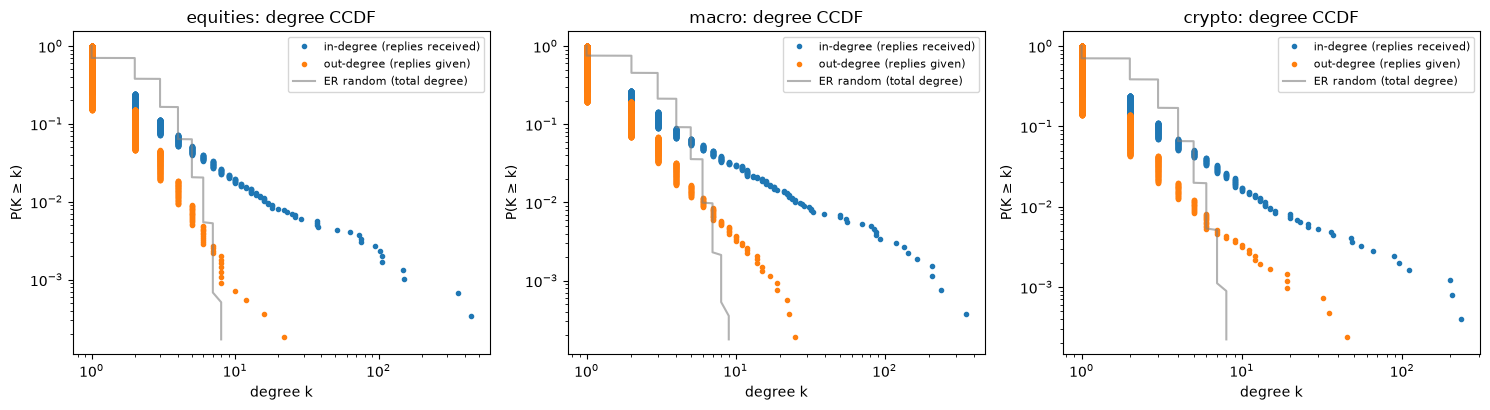

In [10]:
def ccdf(values):
    v = np.sort(np.asarray(values)); v = v[v > 0]
    return v, 1.0 - np.arange(len(v)) / len(v)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, name in zip(axes, ["equities", "macro", "crypto"]):
    G = graphs[name]
    for label, deg in [("in-degree (replies received)", dict(G.in_degree()).values()),
                       ("out-degree (replies given)", dict(G.out_degree()).values())]:
        x, y = ccdf(list(deg)); ax.loglog(x, y, marker=".", linestyle="none", label=label)
    ER = nx.gnm_random_graph(G.number_of_nodes(), G.number_of_edges(), seed=SEED)
    x, y = ccdf([d for _, d in ER.degree()]); ax.loglog(x, y, color="grey", alpha=0.6, label="ER random (total degree)")
    ax.set_title(f"{name}: degree CCDF"); ax.set_xlabel("degree k"); ax.set_ylabel("P(K ≥ k)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/02_degree_ccdf.png", dpi=150); plt.show()

## 9. Centralities: hubs and brokers


We are trying to determine who is steering the conversation using five different measures.
1) How many people are responding?
2) How many people is it responding to?
3) Is it getting responses from important people?
4) Is it a bridge between different groups?
5) Is it close to everyone?

In [11]:
def centralities(G, giant, k_betweenness=600):
    df = pd.DataFrame(index=list(G.nodes()))
    df["in_degree"]  = pd.Series(dict(G.in_degree()))
    df["out_degree"] = pd.Series(dict(G.out_degree()))
    df["pagerank"]   = pd.Series(nx.pagerank(G, weight="weight"))
    # distance-based measures only make sense on the connected giant component
    df["betweenness"] = pd.Series(nx.betweenness_centrality(giant, k=min(k_betweenness, giant.number_of_nodes()), seed=SEED))
    df["closeness"]   = pd.Series(nx.closeness_centrality(giant))
    df["handle"] = df.index.map(handle_of)
    df["in_giant"] = df.index.isin(giant.nodes())
    return df

cent = centralities(graphs["all"], giants["all"])
cent.to_csv(f"{PROC}/centralities_all.csv")

def top10(df, col):
    return df.nlargest(10, col)[["handle", col]].reset_index(drop=True)

top_tables = {c: top10(cent, c) for c in ["in_degree", "out_degree", "pagerank", "betweenness", "closeness"]}
pd.concat(top_tables, axis=1)

in_degree                             out_degree  \
                        handle in_degree                       handle   
0                  atrupar.com       738      shitcoinape.bsky.social   
1              meidastouch.com       391        johndurux.bsky.social   
2          muellershewrote.com       373  liquidation-lol.bsky.social   
3  carlquintanilla.bsky.social       280       snabbkassa.bsky.social   
4  disabilitystor1.bsky.social       233                  bot-tan.com   
5     angrystaffer.bsky.social       233          skyla50.bsky.social   
6      kevinmkruse.bsky.social       223            cgd-2.bsky.social   
7       joemcjoe11.bsky.social       209        cascoinfoundation.org   
8                   popbase.tv       200      journeyled1.bsky.social   
9          rbreich.bsky.social       172        tcoop6231.bsky.social   

                                 pagerank            \
  out_degree                       handle  pagerank   
0         45          muellershewrote.com  0.017201   
1         36  disabilitystor1.bsky.social  0.011970   
2         32                  atrupar.com  0.010932   
3         26      kevinmkruse.bsky.social  0.009417   
4         26       swmseattle.bsky.social  0.007988   
5         25     loripeterson.bsky.social  0.007986   
6         25    loumannheim87.bsky.social  0.006405   
7         22              meidastouch.com  0.005564   
8         22     alanahpearce.bsky.social  0.005287   
9         22       wrenwalker.bsky.social  0.005099   

                   betweenness                                closeness  \
                        handle betweenness                       handle   
0                  atrupar.com    0.278894                  atrupar.com   
1              meidastouch.com    0.133929              meidastouch.com   
2  carlquintanilla.bsky.social    0.115834  carlquintanilla.bsky.social   
3          muellershewrote.com    0.106510          muellershewrote.com   
4  disabilitystor1.bsky.social    0.099886         davidicw.bsky.social   
5                   forbes.com    0.063113        paulie547.bsky.social   
6     angrystaffer.bsky.social    0.060923          rbreich.bsky.social   
7      kevinmkruse.bsky.social    0.059638      mreddie8976.bsky.social   
8                ketanjoshi.co    0.059563         crampell.bsky.social   
9          rbreich.bsky.social    0.058219                   forbes.com   

             
  closeness  
0  0.264968  
1  0.242891  
2  0.241643  
3  0.239019  
4  0.237045  
5  0.236231  
6  0.234555  
7  0.232941  
8  0.232586  
9  0.229940

In [12]:
import json
from atproto import Client, models
creds = json.load(open("../../secrets/bluesky_credentials.json"))
client = Client(); client.login(creds["HANDLE"], creds["APP_PASSWORD"])
top = cent.nlargest(10, "in_degree")
res = client.app.bsky.actor.get_profiles(models.AppBskyActorGetProfiles.Params(actors=list(top.index)))
bios = pd.DataFrame([{"handle": p.handle, "followers": p.followers_count, "bio": (p.description or "").replace("\n", " ")[:120]} for p in res.profiles])
bios

,handle,followers,bio
0,atrupar.com,969078,"Independent journalist, SnapStream brand ambas..."
1,meidastouch.com,1077664,The fastest growing independent news network i...
2,muellershewrote.com,739536,"Owner of MSW Media, host of The Daily Beans, U..."
3,carlquintanilla.bsky.social,284405,26+ years at @CNBC and @NBCNews / @WSJ alum / ...
4,disabilitystor1.bsky.social,44462,"Historian, occasional anthropologist, working ..."
5,angrystaffer.bsky.social,396027,"Not a WH Staffer | Politics, NatSec, and Snark..."
6,kevinmkruse.bsky.social,395982,Historian: White Flight; New Suburban History;...
7,joemcjoe11.bsky.social,22247,"↑Thank you↑ 22,000! Followed by Luke Skywalke..."
8,popbase.tv,353234,Pop Base is your best source for all pop cultu...
9,rbreich.bsky.social,816221,"Berkeley professor, former Secretary of Labor...."


* Here we conclude that the accounts that got the most replies (atrupar.com, meidastouch.com, muellershewrote.com, carlquintanilla.bsky.social ...) are not financial analysts, they are political/news commentators and journalists (I have researched the users but since we have to be precise with the data I have then added their account type for clarification.)
* The accounts who gave the most replies are totally different and the most active user even only replied 45 different users.

Seeing whether the five measures highlight the same individuals or different ones; and to determine using rank correlation which measures are copies of one another.

In [13]:
# do the rankings agree? Spearman rank correlation between the measures (giant component only)
cent[cent.in_giant][["in_degree", "out_degree", "pagerank", "betweenness", "closeness"]].corr(method="spearman").round(2)

,in_degree,out_degree,pagerank,betweenness,closeness
in_degree,1.00,0.01,0.97,0.55,-0.14
out_degree,0.01,1.00,0.05,0.56,0.26
pagerank,0.97,0.05,1.00,0.51,-0.16
betweenness,0.55,0.56,0.51,1.00,0.21
closeness,-0.14,0.26,-0.16,0.21,1.00


In-degree vs. PageRank (0.97): nearly identical rankings; those receiving many replies are already important figures. In-degree vs. Out-degree (0.01): completely independent; the recipients of replies and the senders of replies are different people. Betweenness shows a moderate correlation with both (0.55 and 0.56): both receiving and sending replies contribute to acting as a bridge. Closeness is distinct from the others, showing a slight negative correlation with in-degree (−0.14) and a slight positive correlation with out-degree (0.26): those who receive the most replies are not at the center of the network, but rather at the center of their own specific crowd.

In [14]:
# brokers: nodes whose betweenness rank is much better than their degree rank
g = cent[cent.in_giant].copy()
g["degree"] = g.in_degree + g.out_degree
g["rank_degree"] = g.degree.rank(ascending=False)
g["rank_betweenness"] = g.betweenness.rank(ascending=False)
g["rank_gap"] = g.rank_degree - g.rank_betweenness
g[g.rank_betweenness <= 50].nlargest(10, "rank_gap")[["handle", "degree", "rank_degree", "betweenness", "rank_betweenness"]].round(4)

,handle,degree,rank_degree,betweenness,rank_betweenness
did:plc:qiqjxf65ixgut4xvb57fsigx,cedichou.bsky.social,2,3582.0,0.0155,40.0
did:plc:rfnb4qauorkjhrvwye7gnfsj,joekalicki.bsky.social,3,1956.5,0.0154,41.0
did:plc:f7ecbflk4w3isvi4bwa27azx,gartmartin9.bsky.social,5,850.0,0.0207,25.0
did:plc:pcx2nhwk5ogq7vg5jf6c5pv4,proudrebelscum.bsky.social,5,850.0,0.0158,39.0
did:plc:lvsjva66657a4fklxxglpfoh,b623.bsky.social,8,411.5,0.0163,37.0
did:plc:muxjzvpy2or3jwxgmfcl46wl,davidicw.bsky.social,9,353.5,0.0198,27.0
did:plc:nckvtp7bqrrpohzuulamijal,paul.ofthenorth.ca,10,304.0,0.0143,44.0
did:plc:t2dhvq4ioyj6giyy36qvpqov,catincognito.bsky.social,10,304.0,0.0128,50.0
did:plc:xjxre2f5tmjq4zzwzmcbm27j,umbrarchist.bsky.social,11,259.0,0.0138,48.0
did:plc:xzyu7rkkh2v7ldlnh7vgorvw,mreddie8976.bsky.social,27,79.5,0.0239,23.0


The few connections these individuals have lead to distinct conversation clusters; a significant portion of the shortest paths between clusters passes through them. They do not overlap at all with the hub list; however, davidicw and mreddie8976 appear in the top 10 for closeness in cell 10, meaning they act as both bridges and nodes close to everyone.

In [15]:
# who receives the most replies inside each stream
per_stream = {}
for s in ["equities", "macro", "crypto"]:
    G = graphs[s]
    top = pd.Series(dict(G.in_degree())).nlargest(8)
    per_stream[s] = pd.DataFrame({"handle": [handle_of.get(d, d) for d in top.index], "in_degree": top.values})
pd.concat(per_stream, axis=1)

equities                                  macro  \
                        handle in_degree                       handle   
0                  atrupar.com       441              meidastouch.com   
1          muellershewrote.com       357                  atrupar.com   
2  carlquintanilla.bsky.social       151     angrystaffer.bsky.social   
3          rbreich.bsky.social       147       joemcjoe11.bsky.social   
4     alanahpearce.bsky.social       106          muellershewrote.com   
5       wrenwalker.bsky.social       105  carlquintanilla.bsky.social   
6           altnps.bsky.social       103       dharmalee3.bsky.social   
7         thesataniccircle.org        95         crampell.bsky.social   

                                  crypto            
  in_degree                       handle in_degree  
0       352  disabilitystor1.bsky.social       233  
1       238      kevinmkruse.bsky.social       205  
2       209                   popbase.tv       200  
3       207                ketanjoshi.co       110  
4       164              zacheverson.com        95  
5       143                  atrupar.com        89  
6       135                   forbes.com        66  
7       120        cascoinfoundation.org        55

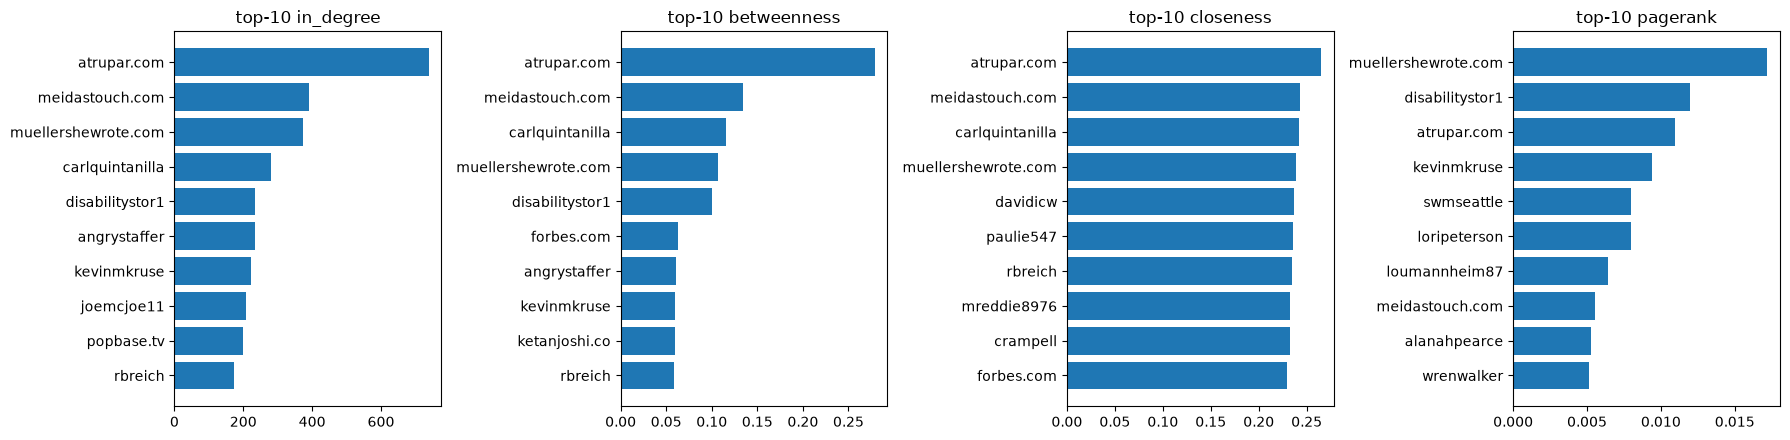

In [16]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))
for ax, col in zip(axes, ["in_degree", "betweenness", "closeness", "pagerank"]):
    t = top10(cent, col).iloc[::-1]
    ax.barh(t.handle.str.replace(".bsky.social", ""), t[col]); ax.set_title(f"top-10 {col}")
plt.tight_layout(); plt.savefig(f"{FIG}/02_top10_centralities.png", dpi=150); plt.show()

The same four names appear at the top of the in-degree, betweenness, and closeness panels (atrupar.com, meidastouch.com, carlquintanilla, muellershewrote.com); divergence occurs further down the lists: less-connected accounts such as davidicw, paulie547, mreddie8976, and crampell appear in the closeness list, while accounts not found in the in-degree top 10—such as swmseattle, loripeterson, and loumannheim87—emerge in the PageRank list.

## 10. Stream comparison figure


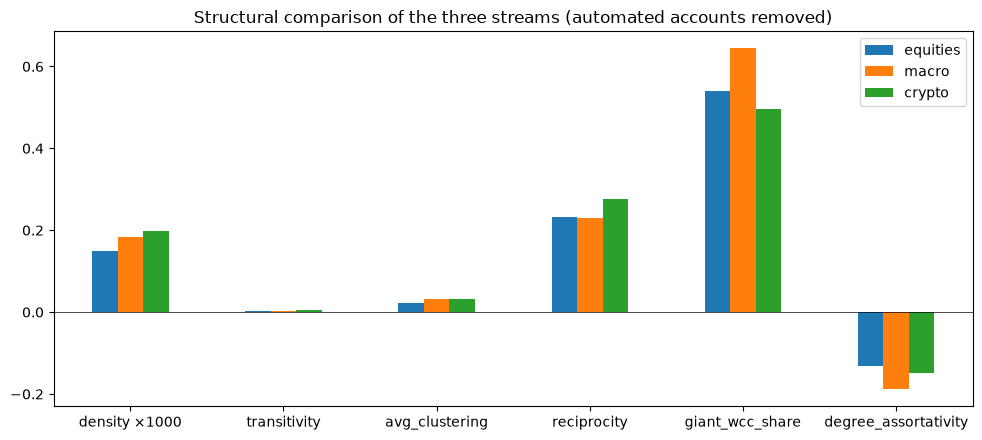

In [17]:
cmp = summary.loc[["equities", "macro", "crypto"], ["density", "transitivity", "avg_clustering", "reciprocity", "giant_wcc_share", "degree_assortativity"]].copy()
cmp["density"] = cmp["density"] * 1000     # scaled to be visible next to the others
cmp = cmp.rename(columns={"density": "density ×1000"})
ax = cmp.T.plot(kind="bar", figsize=(10, 4.5), rot=0)
ax.set_title("Structural comparison of the three streams (automated accounts removed)"); ax.axhline(0, color="black", lw=0.5)
plt.tight_layout(); plt.savefig(f"{FIG}/02_stream_comparison.png", dpi=150); plt.show()
summary.round(4).to_csv(f"{PROC}/network_summary.csv")

## 11. Save node and edge tables for the next notebooks


In [18]:
# stream activity per author (how many of their posts fall in each stream) → used later as a node attribute
stream_counts = (posts.explode("streams").groupby(["author_did", "streams"]).size().unstack(fill_value=0))
nodes = cent.join(stream_counts, how="left").fillna({"equities": 0, "macro": 0, "crypto": 0})
nodes["dominant_stream"] = nodes[["equities", "macro", "crypto"]].idxmax(axis=1).where(nodes[["equities", "macro", "crypto"]].sum(axis=1) > 0, "reply-only")
nodes.index.name = "did"
nodes.to_csv(f"{PROC}/nodes_all.csv")
authors.to_csv(f"{PROC}/authors.csv")
allposts["anchor_uri"] = allposts.uri.map(anchor_uri)
allposts["anchor_offtopic"] = allposts.anchor_uri.map(flags.offtopic).fillna(False).astype(bool)
allposts.to_pickle(f"{PROC}/allposts.pkl")
with open(f"{PROC}/graphs.pkl", "wb") as f:
    pickle.dump({"graphs": graphs, "giants": giants, "G_with_bots": G_with_bots}, f)
nx.write_gexf(graphs["all"], f"{PROC}/reply_network_all.gexf")   # for Gephi, if needed
print(nodes.dominant_stream.value_counts())

dominant_stream
reply-only    9407
equities      2675
macro         2154
crypto        1737
Name: count, dtype: int64
